In [1]:
!pip install --upgrade ultralytics
!pip install --upgrade ray[tune]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.3/78.3 MB 12.5 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import re
import glob
import random
import yaml

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns

# import IPython.display as display
from PIL import Image
import cv2

from ultralytics import YOLO

%matplotlib inline

! wandb disabled

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
wandb: Updated settings file /content/wandb/settings
W&B disabled.


### EDA

In [3]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USER')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

!kaggle datasets download -d thepbordin/indoor-object-detection

Dataset URL: https://www.kaggle.com/datasets/thepbordin/indoor-object-detection
License(s): GNU Lesser General Public License 3.0
100% 367M/367M [00:03<00:00, 125MB/s]



In [4]:
!mkdir -p /content/data
!unzip -o /content/indoor-object-detection.zip -d /content/data

Archive:  /content/indoor-object-detection.zip
  inflating: /content/data/data.yaml  
  inflating: /content/data/test/images/1003.png  
  inflating: /content/data/test/images/1014.png  
  inflating: /content/data/test/images/1015.png  
  inflating: /content/data/test/images/1020.png  
  inflating: /content/data/test/images/1021.png  
  inflating: /content/data/test/images/1023.png  
  inflating: /content/data/test/images/1026.png  
  inflating: /content/data/test/images/1027.png  
  inflating: /content/data/test/images/1028.png  
  inflating: /content/data/test/images/1029.png  
  inflating: /content/data/test/images/1032.png  
  inflating: /content/data/test/images/1034.png  
  inflating: /content/data/test/images/1040.png  
  inflating: /content/data/test/images/1043.png  
  inflating: /content/data/test/images/1045.png  
  inflating: /content/data/test/images/1047.png  
  inflating: /content/data/test/images/1048.png  
  inflating: /content/data/test/images/1052.png  
  inflating: /

In [5]:
class CFG:
    DEBUG = False
    FRACTION = 0.05 if DEBUG else 1.0
    SEED = 42

    # classes
    CLASSES = [
        'door',
        'cabinetDoor',
        'refrigeratorDoor',
        'window',
        'chair',
        'table',
        'cabinet',
        'couch',
        'openedDoor',
        'pole'
    ]

    NUM_CLASSES_TO_TRAIN = len(CLASSES)

    # training
    EPOCHS = 3 if DEBUG else 50
    BATCH_SIZE = 8

    BASE_MODEL = 'yolov9e'
    BASE_MODEL_WEIGHTS = f'{BASE_MODEL}.pt'
    EXP_NAME = f'custom_{EPOCHS}_epochs'

    OPTIMIZER = 'auto'
    LR = 1e-3
    LR_FACTOR = 0.01
    WEIGHT_DECAY = 5e-4
    DROPOUT = 0.0
    PATIENCE = 20
    PROFILE = False
    LABEL_SMOOTHING = 0.0

    # paths
    DATA_YAML = '/content/data/data.yaml'
    OUTPUT_DIR = '/content/data'

Read ```data.yaml``` file to chek if it is properly formatted to be used by Yolo

In [6]:
def read_yaml_file(file_path):
    with open(file_path, 'r') as file:
        try:
            data = yaml.safe_load(file)
            return data
        except yaml.YAMLError as e:
            print("Error reading YAML:", e)
            return None


def print_yaml_data(data):
    formatted_yaml = yaml.dump(data, default_style=False)
    print(formatted_yaml)


file_path = CFG.DATA_YAML
yaml_data = read_yaml_file(file_path)

if yaml_data:
    print_yaml_data(yaml_data)

names:
- door
- cabinetDoor
- refrigeratorDoor
- window
- chair
- table
- cabinet
- couch
- openedDoor
- pole
nc: 10
test: /content/data/test/images
train: /content/data/train/images
val: /content/data/valid/images



Visualize one image

In [7]:
def display_image(image, print_info = True, hide_axis = False):
    if isinstance(image, str):  # Check if it's a file path
        img = Image.open(image)
        plt.imshow(img)
    elif isinstance(image, np.ndarray):  # Check if it's a NumPy array
        image = image[..., ::-1]  # BGR to RGB
        img = Image.fromarray(image)
        plt.imshow(img)
    else:
        raise ValueError("Unsupported image format")

    if print_info:
        print('Type: ', type(img), '\n')
        print('Shape: ', np.array(img).shape, '\n')

    if hide_axis:
        plt.axis('off')

    plt.show()

Type:  <class 'PIL.JpegImagePlugin.JpegImageFile'> 

Shape:  (683, 1024, 3) 



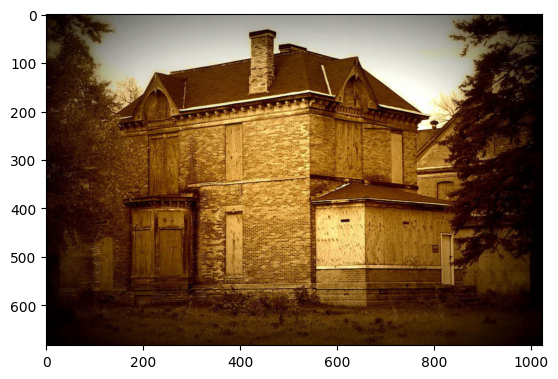

In [8]:
example_image_path = '/content/data/train/images/000c66e044e850f7.jpg'
display_image(example_image_path, print_info = True, hide_axis = False)

Visualize many images

In [9]:
def plot_random_images_from_folder(folder_path, num_images=20, seed=CFG.SEED):

    random.seed(seed)

    # Get a list of image files in the folder
    image_files = [f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.png', '.jpeg', '.gif'))]

    # Ensure that we have at least num_images files to choose from
    if len(image_files) < num_images:
        raise ValueError("Not enough images in the folder")

    # Randomly select num_images image files
    selected_files = random.sample(image_files, num_images)

    # Create a subplot grid
    num_cols = 5
    num_rows = (num_images + num_cols - 1) // num_cols
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(12, 8))

    for i, file_name in enumerate(selected_files):
        # Open and display the image using PIL
        img = Image.open(os.path.join(folder_path, file_name))

        if num_rows == 1:
            ax = axes[i % num_cols]
        else:
            ax = axes[i // num_cols, i % num_cols]

        ax.imshow(img)
        ax.axis('off')
        # ax.set_title(file_name)

    # Remove empty subplots
    for i in range(num_images, num_rows * num_cols):
        if num_rows == 1:
            fig.delaxes(axes[i % num_cols])
        else:
            fig.delaxes(axes[i // num_cols, i % num_cols])

    plt.tight_layout()
    plt.show()

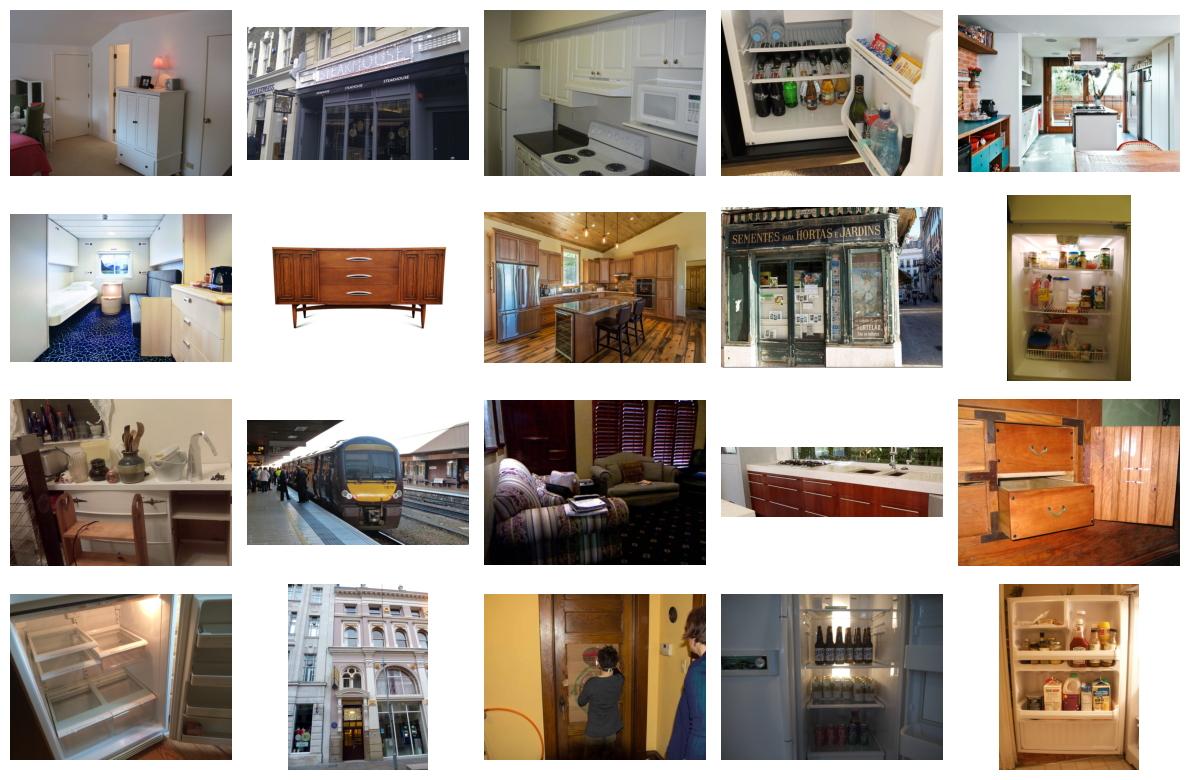

In [10]:
folder_path = 'data/train/images/'
plot_random_images_from_folder(folder_path, num_images=20, seed=CFG.SEED)

Image properties

In [11]:
def get_image_properties(image_path):
    # Read the image file
    img = cv2.imread(image_path)

    # Check if the image file is read successfully
    if img is None:
        raise ValueError("Could not read image file")

    # Get image properties
    properties = {
        "width": img.shape[1],
        "height": img.shape[0],
        "channels": img.shape[2] if len(img.shape) == 3 else 1,
        "dtype": img.dtype,
    }

    return properties

In [12]:
img_properties = get_image_properties(example_image_path)
img_properties

{'width': 1024, 'height': 683, 'channels': 3, 'dtype': dtype('uint8')}

Dataset statistics

In [13]:
class_idx = {
    str(i): CFG.CLASSES[i]
    for i in range(CFG.NUM_CLASSES_TO_TRAIN)
}

class_stat = {}
data_len = {}
class_info = []

for mode in ['train', 'valid', 'test']:

    class_count = {
        CFG.CLASSES[i]: 0
        for i in range(CFG.NUM_CLASSES_TO_TRAIN)
    }


    path = f'/content/data/{mode}/labels'

    for file in os.listdir(path):

        file_path = os.path.join(path, file)

        with open(file_path) as f:
            lines = f.readlines()

            for line in lines:
                cls = line.strip().split()[0]

                if cls in class_idx:
                    class_count[class_idx[cls]] += 1

    data_len[mode] = len(os.listdir(path))
    class_stat[mode] = class_count

    class_info.append({
        'Mode': mode,
        **class_count,
        'Data_Volume': data_len[mode]
    })


dataset_stats_df = pd.DataFrame(class_info)

with pd.option_context('display.max_columns', None):
    display(dataset_stats_df)


,Mode,door,cabinetDoor,refrigeratorDoor,window,chair,table,cabinet,couch,openedDoor,pole,Data_Volume
0,train,479,3178,689,403,204,228,179,27,78,27,1008
1,valid,97,765,192,91,49,40,32,1,13,9,230
2,test,34,179,2,63,87,47,52,58,20,8,104


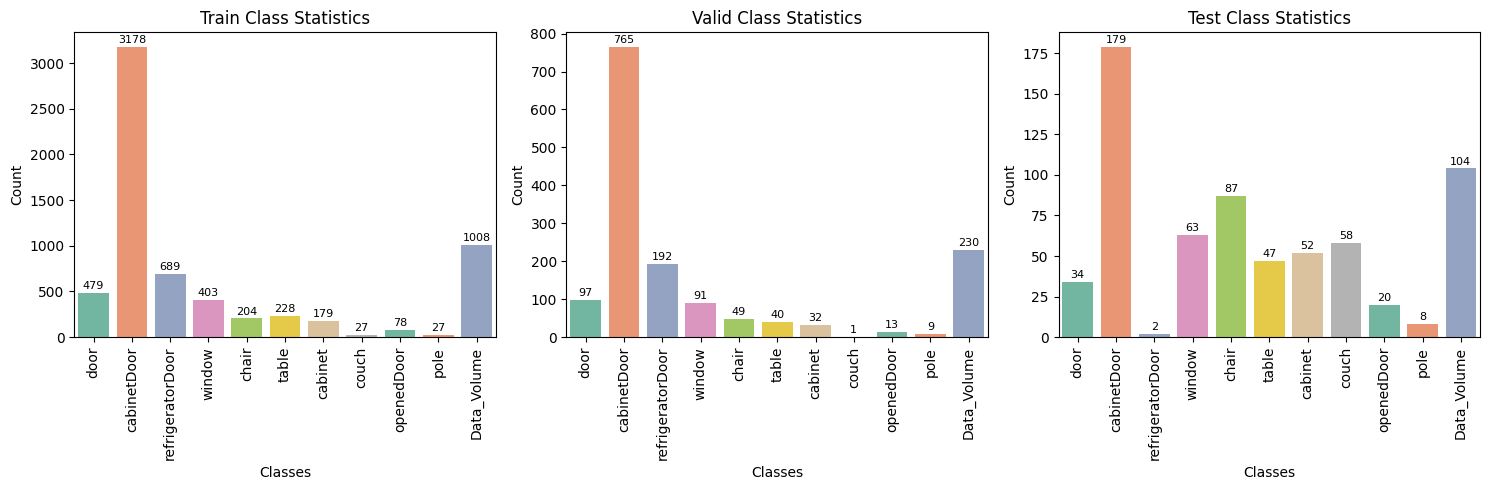

In [14]:
# Create subplots with 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot vertical bar plots for each mode in subplots
for i, mode in enumerate(['train', 'valid', 'test']):
    sns.barplot(
        data=dataset_stats_df[dataset_stats_df['Mode'] == mode].drop(columns='Mode'),
        orient='v',
        ax=axes[i],
        palette='Set2'
    )

    axes[i].set_title(f'{mode.capitalize()} Class Statistics')
    axes[i].set_xlabel('Classes')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=90)

    # Add annotations on top of each bar
    for p in axes[i].patches:
        axes[i].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', fontsize=8, color='black', xytext=(0, 5),
                         textcoords='offset points')

plt.tight_layout()
plt.show()

Base Model Inference

Checking the power of the pretrained model inference on the CSS dataset

In [15]:
model = YOLO(CFG.BASE_MODEL_WEIGHTS)

results = model.predict(
    source = example_image_path,

    conf = 0.30,
    device = 0,
    imgsz = (img_properties['height'], img_properties['width']),

    save = True,
    save_txt = True,
    save_conf = True,
    exist_ok = True,
)


WARNING ⚠️ imgsz=[683, 1024] must be multiple of max stride 32, updating to [704, 1024]
image 1/1 /content/data/train/images/000c66e044e850f7.jpg: 704x1024 (no detections), 127.0ms
Speed: 93.1ms preprocess, 127.0ms inference, 6.0ms postprocess per image at shape (1, 3, 704, 1024)
Results saved to /content/runs/detect/predict
0 label saved to /content/runs/detect/predict/labels


Type:  <class 'PIL.JpegImagePlugin.JpegImageFile'> 

Shape:  (683, 1024, 3) 



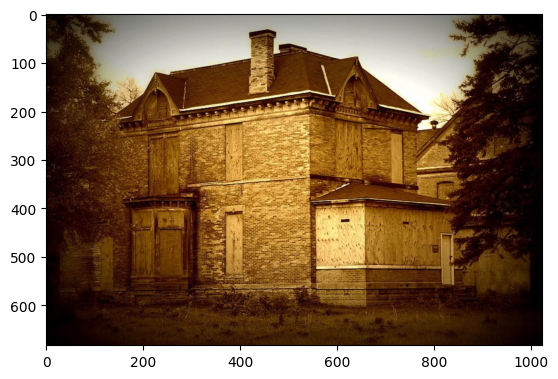

In [16]:
### check predictions with base model
example_image_inference_output = example_image_path.split('/')[-1]
display_image(f'runs/detect/predict/{example_image_inference_output}')

Train

[Arguments for training](https://docs.ultralytics.com/modes/train/#arguments)

In [17]:
print('Model: ', CFG.BASE_MODEL_WEIGHTS)
print('Epochs: ', CFG.EPOCHS)
print('Batch: ', CFG.BATCH_SIZE)

Model:  yolov9e.pt
Epochs:  50
Batch:  8


In [18]:
### Load pre-trained YOLO model
model = YOLO(CFG.BASE_MODEL_WEIGHTS)

In [19]:
### train
model.train(
    data='/content/data/data.yaml',

    task='detect',

    imgsz=640,

    epochs=CFG.EPOCHS,
    batch=CFG.BATCH_SIZE,

    optimizer=CFG.OPTIMIZER,

    lr0=CFG.LR,
    lrf=CFG.LR_FACTOR,
    weight_decay=CFG.WEIGHT_DECAY,
    dropout=CFG.DROPOUT,

    fraction=CFG.FRACTION,
    patience=CFG.PATIENCE,

    profile=CFG.PROFILE,
    label_smoothing=CFG.LABEL_SMOOTHING,

    name=f'{CFG.BASE_MODEL}_{CFG.EXP_NAME}',
    seed=CFG.SEED,

    val=True,
    amp=True,

    exist_ok=True,
    resume=False,

    device=0,

    verbose=True,
)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9e.pt, momentum=0.937, mosaic=1.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c5576efb700>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

Train results

In [21]:
results_paths = [
    i for i in
    glob.glob(f'runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.png') +
    glob.glob(f'runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.jpg')
    if 'batch' not in i
]

results_paths

['runs/detect/yolov9e_custom_50_epochs/confusion_matrix.png',
 'runs/detect/yolov9e_custom_50_epochs/confusion_matrix_normalized.png',
 'runs/detect/yolov9e_custom_50_epochs/BoxPR_curve.png',
 'runs/detect/yolov9e_custom_50_epochs/results.png',
 'runs/detect/yolov9e_custom_50_epochs/BoxR_curve.png',
 'runs/detect/yolov9e_custom_50_epochs/BoxP_curve.png',
 'runs/detect/yolov9e_custom_50_epochs/BoxF1_curve.png',
 'runs/detect/yolov9e_custom_50_epochs/labels.jpg']

runs/detect/yolov9e_custom_50_epochs/BoxF1_curve.png


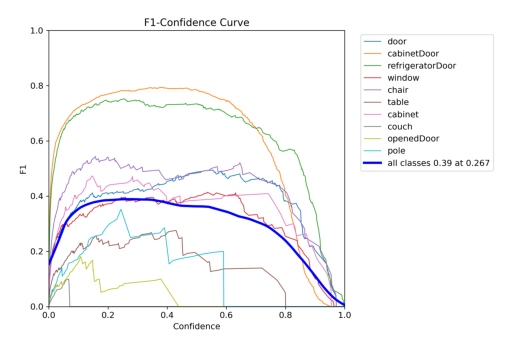



runs/detect/yolov9e_custom_50_epochs/BoxPR_curve.png


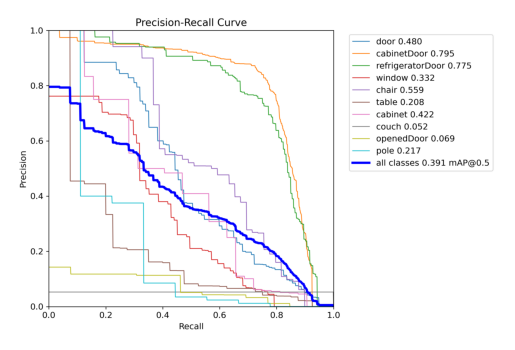



runs/detect/yolov9e_custom_50_epochs/BoxP_curve.png


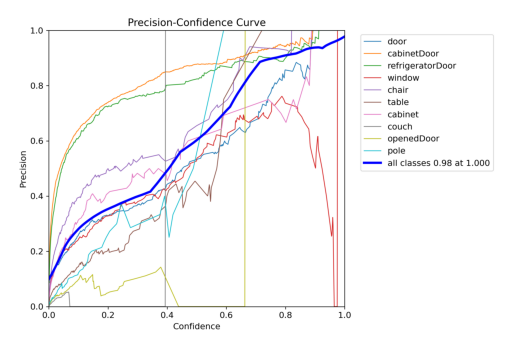



runs/detect/yolov9e_custom_50_epochs/BoxR_curve.png


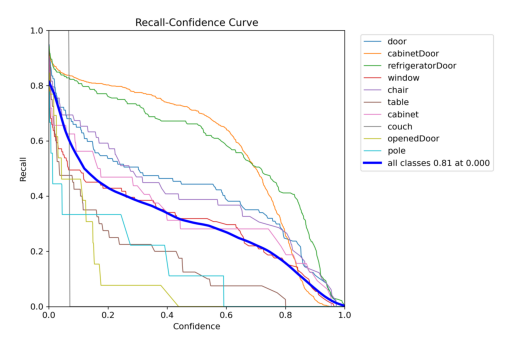



runs/detect/yolov9e_custom_50_epochs/confusion_matrix.png


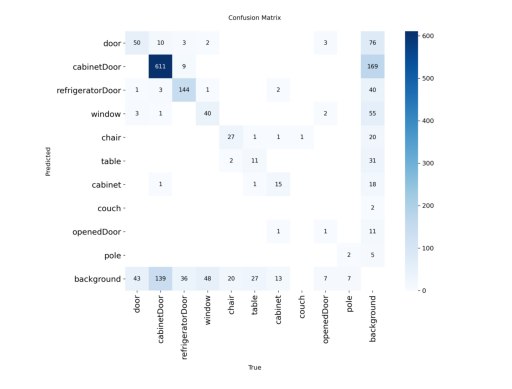



runs/detect/yolov9e_custom_50_epochs/confusion_matrix_normalized.png


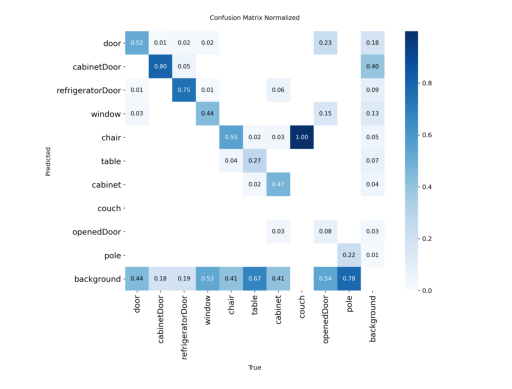



runs/detect/yolov9e_custom_50_epochs/labels.jpg


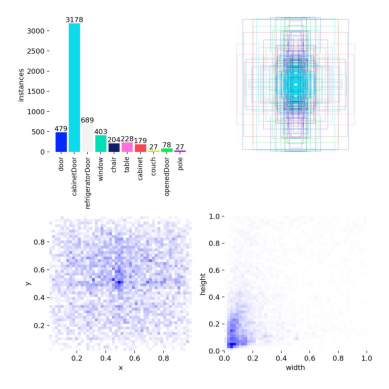



runs/detect/yolov9e_custom_50_epochs/results.png


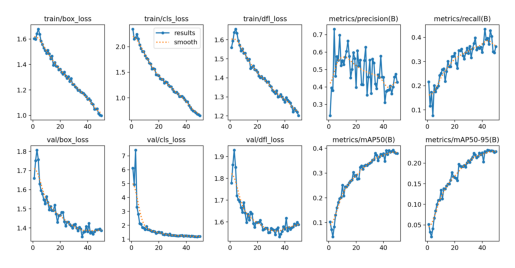

In [22]:
for file in sorted(results_paths):
    print(file)
    display_image(file, print_info = False, hide_axis = True)
    print('\n')

Loss

- The loss function in YOLO consists of three main components: box loss, class loss (cls loss), and objectness loss (dfl loss).
- The total loss in YOLO is a combination of these three components

___

**Box loss:**
- The box loss measures how accurately the predicted bounding box coordinates match the ground truth bounding box.
- Is typically computed using a regression loss, such as Mean Squared Error (MSE), between the predicted bounding box coordinates (center coordinates, width, and height) and the ground truth bounding box coordinates.

___

**Class loss (cls):**
- The class loss measures how well the predicted class probabilities match the true class labels.
- The class loss is usually computed using a categorical cross-entropy loss, which penalizes the difference between the predicted class probabilities and the true class labels.

___

**Objectness loss (dfl):**
- Distribution Focal Loss
- YOLO predicts an "objectness" score for each bounding box, indicating the presence of an object within the grid cell. This score helps filter out irrelevant bounding boxes.
- The objectness loss is calculated based on the difference between the predicted objectness score and the ground truth objectness label. It penalizes the model for false positives and false negatives in predicting the presence of an object.

In [23]:
df = pd.read_csv(f'runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/results.csv')
df = df.rename(columns=lambda x: x.replace(" ", ""))
df.to_csv(f'training_log_df.csv', index=False)
df

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,123.836,1.60271,2.34440,1.55894,0.23540,0.21609,0.10268,0.05137,1.65939,6.11345,1.77840,0.000236,0.000236,0.000236
1,2,257.333,1.59763,2.14646,1.59381,0.39516,0.11596,0.07229,0.03263,1.75215,4.93256,1.86203,0.000465,0.000465,0.000465
2,3,385.428,1.64264,2.17072,1.63823,0.38008,0.17278,0.04282,0.02129,1.80698,7.41300,1.92945,0.000684,0.000684,0.000684
3,4,521.045,1.67852,2.24143,1.65655,0.73239,0.07609,0.08285,0.04083,1.75766,3.30355,1.85099,0.000672,0.000672,0.000672
4,5,690.617,1.63732,2.15071,1.63420,0.46170,0.20100,0.13026,0.06671,1.62998,2.79802,1.71998,0.000657,0.000657,0.000657
5,6,863.504,1.58268,2.03358,1.59451,0.57528,0.17460,0.16000,0.08390,1.59568,2.12147,1.70182,0.000643,0.000643,0.000643
6,7,1032.860,1.55739,1.96249,1.57180,0.55360,0.19157,0.18123,0.09955,1.57865,2.07066,1.69364,0.000629,0.000629,0.000629
7,8,1224.530,1.52931,1.90661,1.54179,0.69688,0.19895,0.19696,0.10981,1.54771,1.84552,1.66599,0.000615,0.000615,0.000615
8,9,1399.380,1.51031,1.90636,1.55231,0.52295,0.24269,0.20145,0.11006,1.52631,1.81516,1.64383,0.000601,0.000601,0.000601
9,10,1553.680,1.48768,1.82438,1.52923,0.55064,0.25111,0.25078,0.13425,1.56443,1.68228,1.68930,0.000587,0.000587,0.000587


```

Class               Images  Instances     Box(P)          R      mAP50   mAP50-95
all                    230       1289      0.383      0.396      0.391      0.232
door                    63         97      0.348      0.505      0.480      0.304
cabinetDoor             99        765      0.776      0.788      0.795      0.455
refrigeratorDoor        85        192      0.751      0.734      0.775      0.530
window                  39         91      0.371      0.396      0.332      0.208
chair                   24         49      0.515      0.510      0.559      0.287
table                   30         40      0.230      0.225      0.208      0.109
cabinet                 28         32      0.434      0.469      0.422      0.302
couch                    1          1      0.000      0.000     0.0524     0.0142
openedDoor              13         13     0.0942     0.0769     0.0694     0.0329
pole                     4          9      0.310      0.252      0.217     0.0774
```

In [24]:
print('*'*50)
print('\nBest Training Box loss: ', df['train/box_loss'].min(), ', on epoch: ', df['train/box_loss'].argmin() + 1, '\n')
print('\nBest Validation Box loss: ', df['val/box_loss'].min(), ', on epoch: ', df['val/box_loss'].argmin() + 1, '\n')

print('='*50)
print('\nBest Training Cls loss: ', df['train/cls_loss'].min(), ', on epoch: ', df['train/cls_loss'].argmin() + 1, '\n')
print('\nBest Validation Cls loss: ', df['val/cls_loss'].min(), ', on epoch: ', df['val/cls_loss'].argmin() + 1, '\n')

print('='*50)
print('\nBest Training DFL loss: ', df['train/dfl_loss'].min(), ', on epoch: ', df['train/dfl_loss'].argmin() + 1, '\n')
print('\nBest Validation DFL loss: ', df['val/dfl_loss'].min(), ', on epoch: ', df['val/dfl_loss'].argmin() + 1, '\n')

**************************************************

Best Training Box loss:  0.99769 , on epoch:  50 


Best Validation Box loss:  1.35423 , on epoch:  36 


Best Training Cls loss:  0.65137 , on epoch:  50 


Best Validation Cls loss:  1.17119 , on epoch:  48 


Best Training DFL loss:  1.20144 , on epoch:  50 


Best Validation DFL loss:  1.5323 , on epoch:  36 



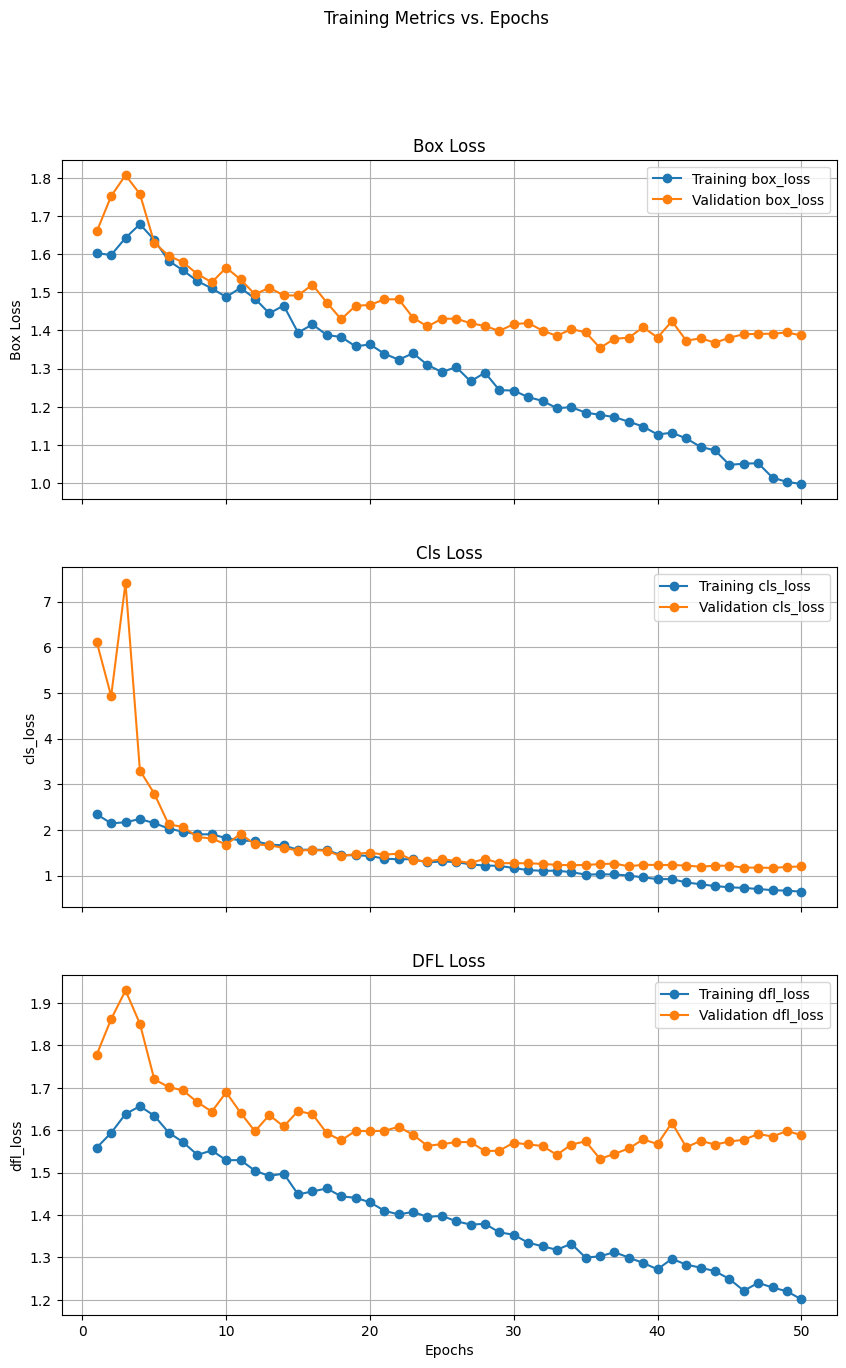

In [25]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

### Training and Validation box_loss
ax1.set_title('Box Loss')
ax1.plot(df['epoch'], df['train/box_loss'], label='Training box_loss', marker='o', linestyle='-')
ax1.plot(df['epoch'], df['val/box_loss'], label='Validation box_loss', marker='o', linestyle='-')
ax1.set_ylabel('Box Loss')
ax1.legend()
ax1.grid(True)

### Training and Validation cls_loss
ax2.set_title('Cls Loss')
ax2.plot(df['epoch'], df['train/cls_loss'], label='Training cls_loss', marker='o', linestyle='-')
ax2.plot(df['epoch'], df['val/cls_loss'], label='Validation cls_loss', marker='o', linestyle='-')
ax2.set_ylabel('cls_loss')
ax2.legend()
ax2.grid(True)

### Training and Validation dfl_loss
ax3.set_title('DFL Loss')
ax3.plot(df['epoch'], df['train/dfl_loss'], label='Training dfl_loss', marker='o', linestyle='-')
ax3.plot(df['epoch'], df['val/dfl_loss'], label='Validation dfl_loss', marker='o', linestyle='-')
ax3.set_xlabel('Epochs')
ax3.set_ylabel('dfl_loss')
ax3.legend()
ax3.grid(True)

plt.suptitle('Training Metrics vs. Epochs')
plt.show()

Validation results

In [27]:
validation_results_paths = [
    i for i in
    glob.glob(f'runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.png') +
    glob.glob(f'runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.jpg')
    if 'val_batch' in i
]

len(validation_results_paths)

6

In [28]:
if len(validation_results_paths) >= 1:
    print(validation_results_paths[-1])

runs/detect/yolov9e_custom_50_epochs/val_batch0_labels.jpg


runs/detect/yolov9e_custom_50_epochs/val_batch0_labels.jpg


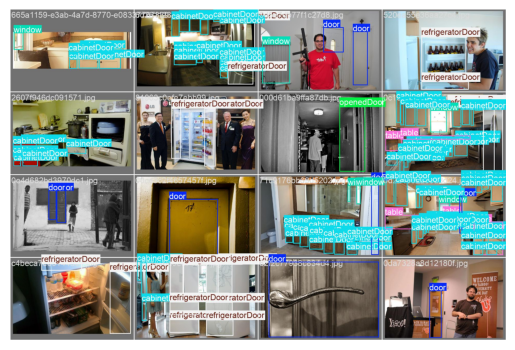

In [29]:
### check predictions or labels from a random validation batch
if len(validation_results_paths) >= 1:
    val_img_path = random.choice(validation_results_paths)
    print(val_img_path)
    display_image(val_img_path, print_info = False, hide_axis = True)

ВИСНОВКИ

У ході виконання завдання було створено робочий прототип системи комп'ютерного зору на базі YOLOv9e. За 50 епох навчання модель показала базовий рівень розпізнавання: загальний mAP50 досяг приблизно 39%, а mAP50-95 склав 23%. Тренувальні втрати падали протягом усього часу, проте на валідації модель вийшла на плато десь після 40–45 епохи. Головна проблема полягає в сильному дисбалансі даних між різними класами. Найкраще модель розпізнає дверцята шаф і холодильників (mAP близько 77–79%), оскільки для них було найбільше прикладів у розмітці. Натомість такі класи, як диван, стовп чи відкриті двері, мережа майже не вивчила через малу кількість зразків. Крім того, модель постійно плутає між собою схожі категорії, наприклад, звичайні двері та відкриті двері, або шафу та її дверцята. Для такої важкої архітектури, як YOLOv9e з 57 мільйонами параметрів, датасет із 230 картинок занадто малий, тому вона просто перенавчилася на кількох найчастіших об'єктах. На майбутнє варто або зібрати більше прикладів для рідкісних класів, або об'єднати проблемні категорії.